In [ ]:
import numpy as np
import skimage
import utils
import pathlib

In [63]:
import matplotlib.pyplot as plt

def plot_histogram(histogram, L, title=""):
    fig, ax = plt.subplots(1,1)
    indices = [i for i in range(L)]
    plt.plot(indices, histogram)
    plt.title(title)
    plt.show()

def otsu_thresholding(im: np.ndarray) -> int:
    """
        Otsu's thresholding algorithm that segments an image into 1 or 0 (True or False)
        The function takes in a grayscale image and outputs a threshold value

        args:
            im: np.ndarray of shape (H, W) in the range [0, 255] (dtype=np.uint8)
        return:
            (int) the computed thresholding value
    """
    assert im.dtype == np.uint8
    ### START YOUR CODE HERE ### (You can change anything inside this block) 
    # You can also define other helper functions
    L = 256

    # Compute normalized histogram of the input image
    M, N = im.shape
    normalized_histogram = [0 for k in range(L)]
    for i in range(M):
        for j in range(N):
            intensity = im[i][j]
            normalized_histogram[intensity] += 1
    # plot_histogram(normalized_histogram, L, "Normalized histogram")

    p = [normalized_histogram[i]/(N*M) for i in range(L)]
    # plot_histogram(p, L, "Probabilities")

    # Compute cumulative sums
    P_1 = [0 for k in range(L)]
    P_1[0] = p[0]
    for k in range(1, L):
        P_1[k] = P_1[k-1] + p[k]
    # plot_histogram(P_1, L, "Cumulative sums")

    # Compute cumulative means
    m = [0 for k in range(L)]
    for k in range(1, L):
        m[k] = m[k-1] + k*p[k]
    # plot_histogram(m, L, "Cumulative means")

    # Compute the global mean
    m_G = m[L-1]
    # print("Global mean:", m_G)

    # Compute the between-class variance
    sigma_B_square = [0 for k in range(L)]
    for k in range(L):
        try:
            sigma_B_square[k] = ((m_G*P_1[k] - m[k])**2)/(P_1[k]*(1 - P_1[k]))
        except ZeroDivisionError:
            pass
    # plot_histogram(sigma_B_square, L, "Between-class variance")

    # Obtain Otsu threshold
    max_sigma_B_square = np.max(sigma_B_square)
    k_star = []
    for k in range(L):
        if sigma_B_square[k] == max_sigma_B_square:
            k_star.append(k)
    threshold = np.average(k_star)
    
    
    return threshold
    ### END YOUR CODE HERE ### 

Reading image: images/thumbprint.png
Found optimal threshold: 153.0
Saving image to: image_processed/thumbprint-segmented.png
Reading image: images/rice-shaded.png
Found optimal threshold: 134.0
Saving image to: image_processed/rice-shaded-segmented.png


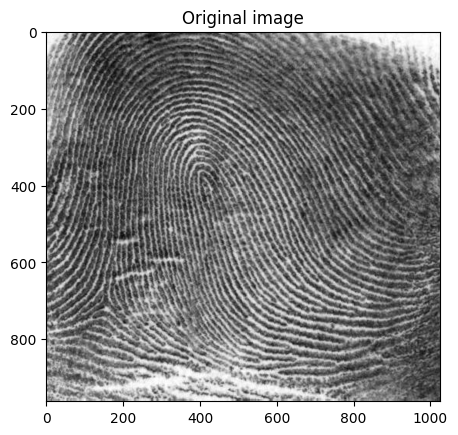

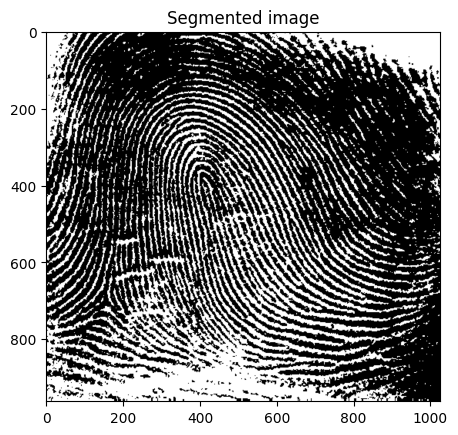

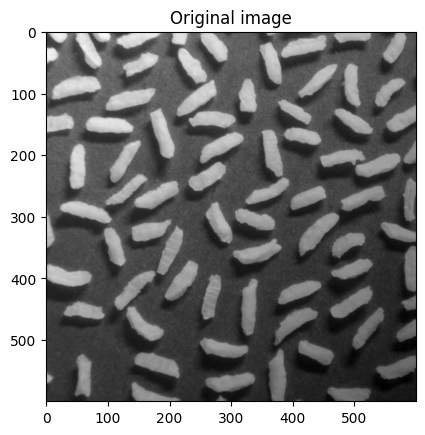

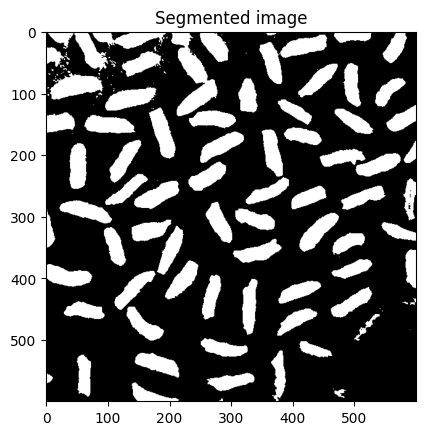

In [64]:
if __name__ == "__main__":
    # DO NOT CHANGE
    impaths_to_segment = [
        pathlib.Path("thumbprint.png"),
        pathlib.Path("rice-shaded.png")
    ]
    for impath in impaths_to_segment:
        im = utils.read_image(impath)
        threshold = otsu_thresholding(im)
        print("Found optimal threshold:", threshold)

        # Segment the image by threshold
        segmented_image = (im >= threshold)
        assert im.shape == segmented_image.shape, "Expected image shape ({}) to be same as thresholded image shape ({})".format(
                im.shape, segmented_image.shape)
        assert segmented_image.dtype == bool, "Expected thresholded image dtype to be bool. Was: {}".format(
                segmented_image.dtype)

        segmented_image = utils.to_uint8(segmented_image)

        fig, ax = plt.subplots(1,1)
        plt.imshow(im, cmap="gray")
        plt.title("Original image")

        fig, ax = plt.subplots(1,1)
        plt.imshow(segmented_image, cmap="gray")
        plt.title("Segmented image")

        save_path = "{}-segmented.png".format(impath.stem)
        utils.save_im(save_path, segmented_image)

        
